# Forward Validation with Manual Soil Thermal Diffusivity

This notebook is separated from `soil_thermal_inverse_methods_v2.ipynb` Section 13. It does **not** estimate `alpha` again. Instead, manually enter the inverse-estimated soil thermal diffusivity, select a validation time interval, run the forward heat-conduction model, and compare observation, forward modeling, and residual contours.

## 1. User Inputs

Edit this cell first. `ALPHA_MANUAL` is the soil thermal diffusivity obtained from a previous inverse-problem calculation. `VALIDATION_START` and `VALIDATION_END` define the simulation interval.

In [11]:
from pathlib import Path
from datetime import datetime
from typing import List
import string
from matplotlib.ticker import FormatStrFormatter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.gridspec as gridspec

from soil_inverse.forward import HeatGrid, active_node_indices, forward_temperature

alphabet = list(string.ascii_lowercase)


CSV_PATH = Path("Lupit_20210729_0812.csv")
RAINFALL_FOLDER = Path("C0U940_20210728-0812")
RESAMPLE_INTERVAL = "10min"

# Manually enter the estimated soil thermal diffusivity [m^2/s].
# ALPHA_MANUAL = 8.919491e-07
ALPHA_MANUAL = 8.05e-07

# Adjustable forward-validation interval.
VALIDATION_START = "2021-08-06 00:00"
VALIDATION_END = "2021-08-09 00:00"

# VALIDATION_START = "2021-08-09 00:00"
# VALIDATION_END = "2021-08-12 00:00"

# Spatial diffusion operator used by the refined implicit solver.
# The updated soil_inverse HeatGrid supports the central operator.
SPACE_SCHEME = "central"

WATER_CONTENT_COLUMNS = ["M1", "M2", "M3", "M4"]
TEMP_COLUMNS = ["T1", "T2", "T3", "T4"]
DEPTHS_M = np.array([0.25, 0.50, 0.75, 1.00], dtype=float)
DENSE_DZ_M = 0.05

OUTPUT_DIR = Path("00_output_figures/05_soil_forward")

alpha_str = str(ALPHA_MANUAL)[:4]
# OUTPUT_FIG = OUTPUT_DIR / "manual_alpha_forward_validation_contours_dry_{}.jpg".format(alpha_str)


OUTPUT_FIG = OUTPUT_DIR / "manual_alpha_forward_validation_contours_wet_{}.jpg".format(alpha_str)

## 2. Load and Resample Data

The raw Lupit time series is resampled to a regular 10-minute grid. Only `T1`, `T2`, `T3`, and `T4` are used in the thermal forward model; `M1`--`M4` are loaded only to preserve the same input format as the main notebook.

In [12]:
def parse_time(value: str) -> datetime:
    formats = [
        "%Y/%m/%d %H:%M",
        "%Y/%m/%d %H:%M:%S",
        "%Y-%m-%d %H:%M",
        "%Y-%m-%d %H:%M:%S",
    ]
    for fmt in formats:
        try:
            return datetime.strptime(str(value), fmt)
        except ValueError:
            pass
    raise ValueError(f"Unsupported datetime format: {value!r}")


def load_and_resample_soil_csv(
    path: Path,
    temp_columns: List[str],
    water_content_columns: List[str],
    resample_interval: str = "10min",
):
    frame = pd.read_csv(path, encoding="utf-8-sig")
    time_column = next((col for col in frame.columns if col.lower() == "time"), None)
    if time_column is None:
        raise ValueError("CSV must contain a time column")

    required = temp_columns + water_content_columns
    missing = [col for col in required if col not in frame.columns]
    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    frame[time_column] = pd.to_datetime(frame[time_column], errors="raise")
    frame = frame.set_index(time_column).sort_index()
    numeric = frame[required].apply(pd.to_numeric, errors="coerce")

    resampled = numeric.resample(resample_interval).mean()
    resampled = resampled.interpolate(method="time", limit_direction="both")

    times = resampled.index.to_pydatetime()
    temperatures = resampled[temp_columns].to_numpy(dtype=float)
    water_content = resampled[water_content_columns].to_numpy(dtype=float)
    return np.array(times, dtype=object), temperatures, water_content, resampled


def load_hourly_rainfall(folder: Path) -> pd.DataFrame:
    """Read hourly C0U940 rainfall files and return a time-indexed Precp DataFrame.

    This follows the original workflow: each CSV is read with header=1 and
    index_col=0; the last hourly label is changed from 24 to 0 before building
    the timestamp from the date embedded in the filename.
    """
    appended_data = []
    for path in sorted(folder.glob("*.csv")):
        daily = pd.read_csv(path, header=1, index_col=0)
        if "Precp" not in daily.columns:
            raise ValueError(f"Missing Precp column in {path}")

        rain_df = pd.DataFrame(pd.to_numeric(daily["Precp"], errors="coerce"))
        rain_df = rain_df.fillna(0.0)

        file_date = pd.to_datetime(path.stem.replace("C0U940-", ""))
        hhlist = rain_df.index.astype(int).tolist()
        if hhlist:
            hhlist[-1] = 0

        date_index = [
            pd.Timestamp(
                year=int(file_date.year),
                month=int(file_date.month),
                day=int(file_date.day),
                hour=int(hh),
            )
            for hh in hhlist
        ]
        rain_df.set_index(pd.Series(date_index), inplace=True)
        appended_data.append(rain_df)

    if not appended_data:
        raise ValueError(f"No rainfall CSV files found in {folder}")

    appended_rain_df = pd.concat(appended_data)
    appended_rain_df = appended_rain_df.sort_index(ascending=True)
    return appended_rain_df


times_all, obs_all, soil_water_content_all, resampled_data = load_and_resample_soil_csv(
    CSV_PATH,
    TEMP_COLUMNS,
    WATER_CONTENT_COLUMNS,
    resample_interval=RESAMPLE_INTERVAL,
)
appended_rainDf = load_hourly_rainfall(RAINFALL_FOLDER)

validation_start = parse_time(VALIDATION_START)
validation_end = parse_time(VALIDATION_END)
if validation_end <= validation_start:
    raise ValueError("VALIDATION_END must be later than VALIDATION_START")

validation_mask = np.array([(validation_start <= t <= validation_end) for t in times_all], dtype=bool)
if not validation_mask.any():
    raise ValueError(f"No observations in validation interval: {validation_start} -> {validation_end}")

times = times_all[validation_mask]
obs_window = obs_all[validation_mask]
water_content_window = soil_water_content_all[validation_mask]
depths = DEPTHS_M.copy()
model_depths = np.arange(depths[0], depths[-1] + 0.5 * DENSE_DZ_M, DENSE_DZ_M)

dt_seconds_all = np.array([(times[i] - times[i - 1]).total_seconds() for i in range(1, len(times))])
dt_seconds = float(np.median(dt_seconds_all))
dz_m = float(np.median(np.diff(depths)))
model_dz_m = float(np.median(np.diff(model_depths)))
analysis_hours = float((times[-1] - times[0]).total_seconds() / 3600.0)
requested_hours = float((validation_end - validation_start).total_seconds() / 3600.0)
rainfall_window = appended_rainDf.loc[validation_start:validation_end].copy()
total_rainfall_mm = float(rainfall_window["Precp"].sum())

print(f"source = {CSV_PATH}")
print(f"rainfall source = {RAINFALL_FOLDER}")
print(f"resample interval = {RESAMPLE_INTERVAL}")
print(f"validation interval = {times[0]} -> {times[-1]}")
print(f"rows = {len(times)}")
print(f"requested hours = {requested_hours:.2f} hr")
print(f"analysis hours = {analysis_hours:.2f} hr")
print(f"total rainfall = {total_rainfall_mm:.3f} mm")
print(f"rainfall records = {len(rainfall_window)}")
print(f"temperature shape = {obs_window.shape}")
print(f"median dt = {dt_seconds:.0f} sec")
print(f"sensor dz = {dz_m:.3f} m")
print(f"dense forward-model dz = {model_dz_m:.3f} m")
print(f"manual alpha = {ALPHA_MANUAL:.6e} m^2/s")

source = Lupit_20210729_0812.csv
rainfall source = C0U940_20210728-0812
resample interval = 10min
validation interval = 2021-08-06 00:00:00 -> 2021-08-09 00:00:00
rows = 433
requested hours = 72.00 hr
analysis hours = 72.00 hr
total rainfall = 47.500 mm
rainfall records = 73
temperature shape = (433, 4)
median dt = 600 sec
sensor dz = 0.250 m
dense forward-model dz = 0.050 m
manual alpha = 8.050000e-07 m^2/s


## 3. Forward Model

The forward model has been updated to use the formal `soil_inverse.forward.HeatGrid` implementation. This solver uses a refined vertical grid and an implicit theta-method; with `theta = 0.5`, the scheme is Crank--Nicolson. The shallowest and deepest temperature sensors are used as time-varying Dirichlet boundaries, and the interior sensor temperatures are predicted by the model.

`DENSE_DZ_M` still controls the vertical grid refinement. Internally it is converted to `cells_per_gap = sensor_gap / DENSE_DZ_M`. The residual is evaluated at the sensor depths as `forward modeling - observation`.

In [13]:
def cells_per_gap_from_dz(depths_m, dz_m):
    diffs = np.diff(np.asarray(depths_m, dtype=float))
    if not np.allclose(diffs, diffs[0]):
        raise ValueError("This helper expects uniformly spaced sensor depths.")
    cells_per_gap_float = diffs[0] / float(dz_m)
    cells_per_gap = int(round(cells_per_gap_float))
    if not np.isclose(cells_per_gap_float, cells_per_gap):
        raise ValueError(f"DENSE_DZ_M={dz_m} does not evenly divide sensor gap={diffs[0]}")
    return cells_per_gap


if SPACE_SCHEME != "central":
    raise ValueError(
        "The updated implicit HeatGrid forward model supports only SPACE_SCHEME='central'. "
        "Set SPACE_SCHEME = 'central'."
    )

cells_per_gap = cells_per_gap_from_dz(depths, DENSE_DZ_M)
grid = HeatGrid(
    depths_m=depths,
    dt_seconds=dt_seconds,
    cells_per_gap=cells_per_gap,
    theta=0.5,
)

# Updated implicit Crank--Nicolson forward model.
# Boundary columns T1 and T4 are prescribed from observations; T2 and T3 are predicted.
pred_window = forward_temperature(ALPHA_MANUAL, obs_window, grid, space_scheme=SPACE_SCHEME)
residual_window = pred_window - obs_window

active_nodes = active_node_indices(obs_window.shape[1], SPACE_SCHEME)
active_residual = residual_window[:, active_nodes]
r_manual = grid.r(ALPHA_MANUAL)

print(f"forward model = soil_inverse.forward.HeatGrid")
print(f"time scheme = implicit theta-method / Crank-Nicolson")
print(f"theta = {grid.theta:.2f}")
print(f"space scheme = {SPACE_SCHEME}")
print(f"sensor active nodes = {active_nodes.tolist()}, depths = {depths[active_nodes].tolist()}")
print(f"cells_per_gap = {cells_per_gap}")
print(f"refined model nodes = {grid.n_cells + 1}, n_cells = {grid.n_cells}, dz = {grid.dz_m:.3f} m")
print(f"r = alpha * dt / dz^2 = {r_manual:.6f}  # reported only; no explicit-CFL stability limit")
print(f"active-node RMSE = {np.sqrt(np.nanmean(active_residual ** 2)):.4f} degC")
print(f"full-grid RMSE = {np.sqrt(np.nanmean(residual_window ** 2)):.4f} degC")


forward model = soil_inverse.forward.HeatGrid
time scheme = implicit theta-method / Crank-Nicolson
theta = 0.50
space scheme = central
sensor active nodes = [1, 2], depths = [0.5, 0.75]
cells_per_gap = 5
refined model nodes = 16, n_cells = 15, dz = 0.050 m
r = alpha * dt / dz^2 = 0.193200  # reported only; no explicit-CFL stability limit
active-node RMSE = 0.1509 degC
full-grid RMSE = 0.1067 degC


## 4. Plot Observation, Forward Modeling, and Residual

The contour panels are ordered from left to right as requested: observation, forward modeling, and residual. The residual is defined as `forward modeling - observation`. The forward-model panel now uses the updated implicit Crank--Nicolson solver from `soil_inverse.forward`.

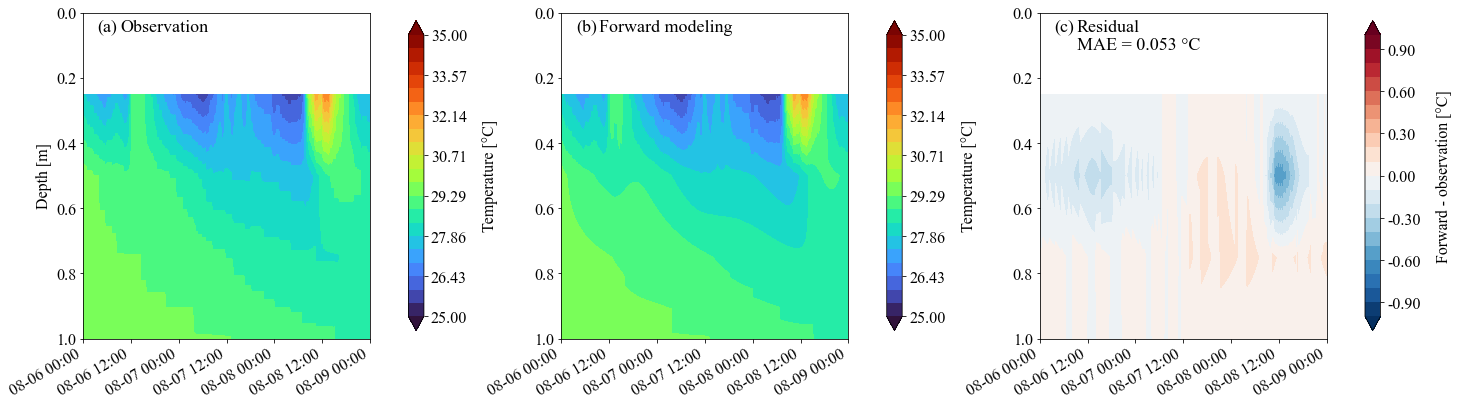

saved figure: 00_output_figures/05_soil_forward/manual_alpha_forward_validation_contours_wet_8.05.jpg


In [14]:
def text_alphabet(handel, w, xx=0.05, yy=0.98):
    handel.text(
        xx,
        yy,
        "({})".format(w),
        transform=handel.transAxes,
        ha="left",
        va="top",
        fontsize=18,
        bbox=dict(facecolor="white", alpha=0.5, edgecolor="none"),
    )
    
def text_txt(handel, w, xx=0.05, yy=0.98):
    handel.text(
        xx,
        yy,
        "{}".format(w),
        transform=handel.transAxes,
        ha="left",
        va="top",
        fontsize=18,
        bbox=dict(facecolor="white", alpha=0.5, edgecolor="none"),
    )


def plot_manual_forward_validation(
    times,
    depths,
    obs,
    pred,
    residual,
    alpha: float,
    space_scheme: str,
    levels: int = 22,
):
    x = mdates.date2num(times)
    X, Z = np.meshgrid(x, depths)

    temp_min = 25
    temp_max = 35
    temp_levels = np.linspace(temp_min, temp_max, levels)

    residual_abs = float(np.nanmax(np.abs(residual)))
    if residual_abs == 0:
        residual_abs = 1.0e-12
    residual_levels = np.linspace(-1, 1, 21)

    # --------------------------------------------- #
    # Figure layout and font control
    fig = plt.figure(figsize=[24, 6])
    plt.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.25, hspace=0.1)
    spec = gridspec.GridSpec(ncols=3, nrows=1, width_ratios=[1, 1, 1])

    plt.rcParams["text.usetex"] = False
    plt.rcParams["mathtext.fontset"] = "cm"
    plt.rcParams["font.family"] = "Times New Roman"

    axes = [fig.add_subplot(spec[0, i]) for i in range(3)]
    panels = [
        (obs.T, "Observation", "turbo", temp_levels, "Temperature [°C]"),
        (pred.T, "Forward modeling", "turbo", temp_levels, "Temperature [°C]"),
        (residual.T, "Residual", "RdBu_r", residual_levels, "Forward - observation [°C]"),
    ]

    for jj, (ax, (values, title, cmap, contour_levels, cbar_label)) in enumerate(zip(axes, panels)):
        cf = ax.contourf(X, Z, values, levels=contour_levels, cmap=cmap, extend="both")
        if title == "Residual":
            averageValues = np.average(np.abs(values))
            title_modi = "{}\nMAE = {:.3f} °C".format(title, averageValues)
            text_txt(ax, title_modi, xx = 0.13)
        else:
            text_txt(ax, title, xx = 0.13)
        
        text_alphabet(ax, alphabet[jj])
        
#         ax.set_title(title, fontsize=14)
#         ax.set_xlabel("Time", fontsize=16)
        ax.xaxis.set_major_locator(mdates.HourLocator(interval=12))
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:00"))
        plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
        cbar = fig.colorbar(cf, ax=ax, shrink=0.95, pad = 0.1)
        cbar.ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))
            
        cbar.set_label(cbar_label, fontsize=16, labelpad=15)
        cbar.ax.tick_params(labelsize=16)
        
        
        ax.tick_params(axis="x", labelsize=16)
        ax.tick_params(axis="y", labelsize=16)
 
        
        ax.set_xlim(validation_start, validation_end)
        ax.set_ylim(0, 1)

    axes[0].set_ylabel("Depth [m]", fontsize=16)
    
    for ax in axes:
        ax.set_ylim(1, 0)
#     fig.suptitle(
#         f"Manual-alpha forward validation: alpha={alpha:.3e} m^2/s, scheme={space_scheme}, "
#         f"interval={times[0]:%Y-%m-%d %H:%M} to {times[-1]:%Y-%m-%d %H:%M}",
#         y=1.04,
#     )
    return fig, values


fig, MAEvalues = plot_manual_forward_validation(
    times,
    depths,
    obs_window,
    pred_window,
    residual_window,
    alpha=ALPHA_MANUAL,
    space_scheme=SPACE_SCHEME,
)

OUTPUT_DIR.mkdir(exist_ok=True)
fig.savefig(OUTPUT_FIG, dpi=1000, bbox_inches="tight")
plt.show()

print("saved figure:", OUTPUT_FIG)